# Book Recommendation System

## Introduction

A Book Recommendation System suggests books
to users based on similarities in their
reading preferences and rating patterns.

This project uses the Book-Crossing dataset
and Item-Based Collaborative Filtering to
recommend books using cosine similarity.

## 1. Importing Libraries

Import the required Python libraries for
data manipulation, visualization and
building the recommendation system.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
!pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import seaborn as sns
def recommend_books(book_title, n=10):

    # Step 1: Find the selected book
    book_data = book_info_filtered[
        book_info_filtered["Book-Title"].str.lower() == book_title.lower()
    ]

    if book_data.empty:
        print("Book not found in the dataset.")
        return

    # Step 2: Find ISBNs available in the recommendation matrix
    available_isbns = set(user_book_matrix.columns.astype(str))

    matching_isbns = [
        str(isbn) for isbn in book_data["ISBN"]
        if str(isbn) in available_isbns
    ]

    if not matching_isbns:
        print("Book is not available in the recommendation matrix.")
        return

    isbn = matching_isbns[0]

    # Step 3: Get the position of the selected book
    book_index = user_book_matrix.columns.astype(str).get_loc(isbn)

    # Step 4: Get similarity scores
    similarity_scores = book_similarity[book_index]

    # Step 5: Sort books by similarity score
    similar_indices = similarity_scores.argsort()[::-1]

    recommendations = []

    # Step 6: Generate top recommendations
    for index in similar_indices:

        if index == book_index:
            continue

        similar_isbn = str(user_book_matrix.columns[index])

        similar_book = book_info_filtered[
            book_info_filtered["ISBN"].astype(str) == similar_isbn
        ]

        if not similar_book.empty:

            recommendations.append({
                "Book Title": similar_book.iloc[0]["Book-Title"],
                "Author": similar_book.iloc[0]["Book-Author"],
                "Similarity Score": round(float(similarity_scores[index]), 4)
            })

        if len(recommendations) == n:
            break

    return pd.DataFrame(recommendations)


## 2. Loading the Dataset

Load the Books, Ratings and Users datasets
using Pandas for further analysis.

In [5]:
books = pd.read_csv(
    r"C:\Users\KP\Desktop\Book_recommendation\data\Books.csv",
    encoding="latin-1",
    on_bad_lines="skip"
)

ratings = pd.read_csv(
    r"C:\Users\KP\Desktop\Book_recommendation\data\Ratings.csv",
    encoding="latin-1",
    on_bad_lines="skip"
)

users = pd.read_csv(
    r"C:\Users\KP\Desktop\Book_recommendation\data\Users.csv",
    encoding="latin-1",
    on_bad_lines="skip"
)

C:\Users\KP\AppData\Local\Temp\ipykernel_21644\2250231525.py:1: DtypeWarning: Columns (0: Year-Of-Publication) have mixed types. Specify dtype option on import or set low_memory=False.
  books = pd.read_csv(


## 3. Understanding the Dataset

Examine the dimensions, structure, columns
and missing values in the datasets.

In [6]:
print("Books:", books.shape)
print("Ratings:", ratings.shape)
print("Users:", users.shape)

Books: (271360, 8)
Ratings: (1149780, 3)
Users: (278858, 3)


In [7]:
books.head()
ratings.head()
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [8]:
books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [9]:
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [10]:
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [11]:
print("Missing values in Books:")
print(books.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

print("\nMissing values in Users:")
print(users.isnull().sum())

Missing values in Books:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

Missing values in Ratings:
User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

Missing values in Users:
User-ID          0
Location         0
Age         110762
dtype: int64


In [12]:
ratings["Book-Rating"].value_counts().sort_index()

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

## 4. Data Cleaning and Preprocessing

Clean the datasets by handling missing
values, removing unnecessary columns and
correcting publication year values.

In [13]:
books_clean = books.copy()
ratings_clean = ratings.copy()
users_clean = users.copy()

In [14]:
books_clean = books_clean.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"]
)

In [15]:
books_clean.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company


In [16]:
books_clean = books_clean.dropna(
    subset=["Book-Author", "Publisher"]
)

In [17]:
books_clean.isnull().sum()

ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
dtype: int64

In [18]:
books_clean["Year-Of-Publication"].value_counts().head(20)

Year-Of-Publication
2002    13902
2001    13714
1999    13413
2000    13373
1998    12116
2003    11610
1997    11494
1996    10687
1995    10258
1994     8857
1993     7920
1992     7390
1991     6926
1990     6394
1989     5825
1988     5545
1987     4761
2004     4629
1986     4258
1999     4017
Name: count, dtype: int64

In [19]:
books_clean["Year-Of-Publication"].unique()[:20]

array([2002, 2001, 1991, 1999, 2000, 1993, 1996, 1988, 2004, 1998, 1994,
       2003, 1997, 1983, 1979, 1995, 1982, 1985, 1992, 1986], dtype=object)

In [20]:
ratings_explicit = ratings_clean[
    ratings_clean["Book-Rating"] > 0
].copy()

In [21]:
print("Original ratings:", ratings_clean.shape)
print("Explicit ratings:", ratings_explicit.shape)

Original ratings: (1149780, 3)
Explicit ratings: (433671, 3)


In [22]:
ratings_explicit["Book-Rating"].value_counts().sort_index()

Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

In [23]:
books_clean["Year-Of-Publication"].value_counts().head(20)

Year-Of-Publication
2002    13902
2001    13714
1999    13413
2000    13373
1998    12116
2003    11610
1997    11494
1996    10687
1995    10258
1994     8857
1993     7920
1992     7390
1991     6926
1990     6394
1989     5825
1988     5545
1987     4761
2004     4629
1986     4258
1999     4017
Name: count, dtype: int64

In [24]:
books_clean["Year-Of-Publication"].unique()[:20]

array([2002, 2001, 1991, 1999, 2000, 1993, 1996, 1988, 2004, 1998, 1994,
       2003, 1997, 1983, 1979, 1995, 1982, 1985, 1992, 1986], dtype=object)

In [25]:
books_clean["Year-Of-Publication"] = pd.to_numeric(
    books_clean["Year-Of-Publication"],
    errors="coerce"
)

In [26]:
books_clean["Year-Of-Publication"].isnull().sum()

np.int64(3)

In [27]:
books_clean["Year-Of-Publication"].describe()

count    271353.000000
mean       1959.760235
std         257.996082
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

In [28]:
books_clean["Year-Of-Publication"].sort_values().head(20)

225373    0.0
250468    0.0
121581    0.0
20171     0.0
170187    0.0
121437    0.0
121440    0.0
121421    0.0
192629    0.0
192599    0.0
192610    0.0
52950     0.0
52960     0.0
121342    0.0
225317    0.0
65256     0.0
121650    0.0
255074    0.0
101865    0.0
9681      0.0
Name: Year-Of-Publication, dtype: float64

In [29]:
books_clean["Year-Of-Publication"].sort_values().tail(20)

238817    2020.0
30010     2020.0
92156     2020.0
183769    2021.0
246842    2024.0
118294    2026.0
78168     2030.0
55676     2030.0
260974    2030.0
240169    2030.0
192993    2030.0
37487     2030.0
228173    2030.0
255409    2037.0
116053    2038.0
97826     2050.0
80264     2050.0
209538       NaN
220731       NaN
221678       NaN
Name: Year-Of-Publication, dtype: float64

In [30]:
books_clean.loc[
    (books_clean["Year-Of-Publication"] < 1900) |
    (books_clean["Year-Of-Publication"] > 2024),
    "Year-Of-Publication"
] = np.nan

In [31]:
books_clean["Year-Of-Publication"].describe()

count    266719.000000
mean       1993.693554
std           8.138069
min        1900.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2024.000000
Name: Year-Of-Publication, dtype: float64

In [32]:
books_clean["Year-Of-Publication"].isnull().sum()

np.int64(4637)

## 5. Exploratory Data Analysis (EDA)

Explore book ratings, popular books,
average ratings and user activity to
understand the dataset.

In [33]:
book_rating_counts = ratings_explicit.groupby("ISBN").size().sort_values(
    ascending=False
)

book_rating_counts.head(10)

ISBN
0316666343    707
0971880107    581
0385504209    487
0312195516    383
0679781587    333
0060928336    320
059035342X    313
0142001740    307
0446672211    295
044023722X    281
dtype: int64

In [34]:
most_rated_books = (
    ratings_explicit.groupby("ISBN")
    .size()
    .reset_index(name="Rating-Count")
    .merge(
        books_clean[["ISBN", "Book-Title", "Book-Author"]],
        on="ISBN",
        how="left"
    )
    .sort_values("Rating-Count", ascending=False)
)

most_rated_books.head(10)

,ISBN,Rating-Count,Book-Title,Book-Author
26378,0316666343,707,The Lovely Bones: A Novel,Alice Sebold
132534,0971880107,581,Wild Animus,Rich Shapero
44961,0385504209,487,The Da Vinci Code,Dan Brown
22405,0312195516,383,The Red Tent (Bestselling Backlist),Anita Diamant
90207,0679781587,333,NaN,NaN
5269,0060928336,320,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells
77942,059035342X,313,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling
15990,0142001740,307,The Secret Life of Bees,Sue Monk Kidd
58853,0446672211,295,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts
54839,044023722X,281,A Painted House,John Grisham


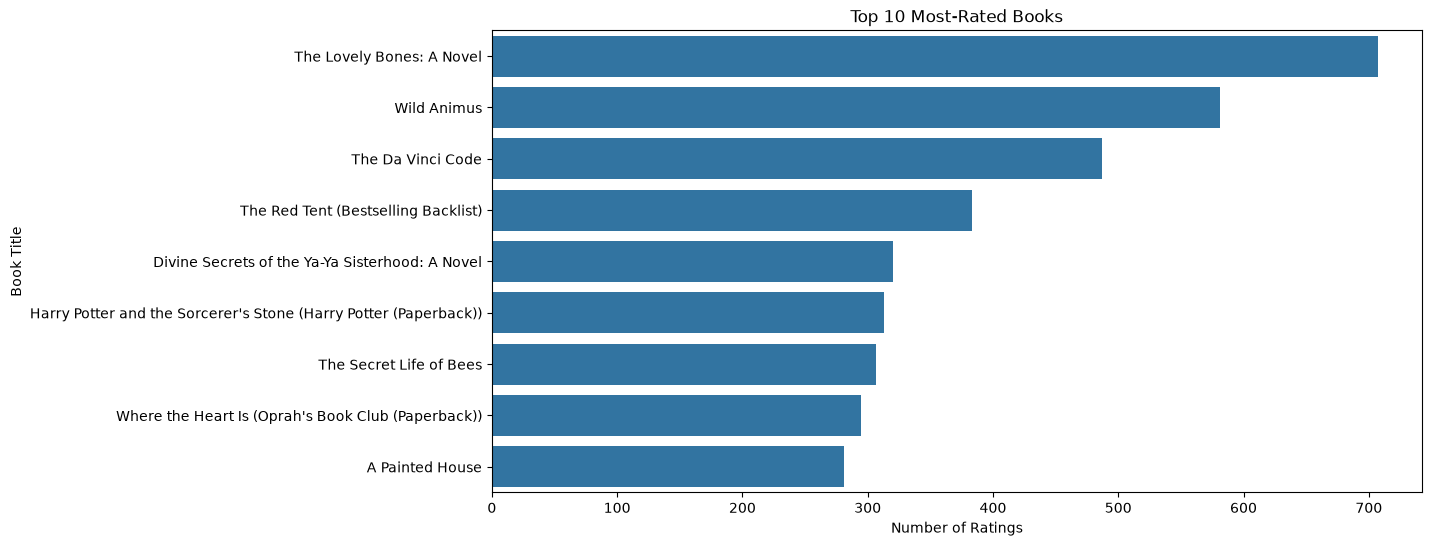

In [35]:
top_10 = most_rated_books.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="Rating-Count",
    y="Book-Title"
)

plt.title("Top 10 Most-Rated Books")
plt.xlabel("Number of Ratings")
plt.ylabel("Book Title")

plt.show()

In [36]:
books_clean.loc[
    (books_clean["Year-Of-Publication"] < 1900) |
    (books_clean["Year-Of-Publication"] > 2024),
    "Year-Of-Publication"
] = np.nan

In [37]:
book_rating_stats = (
    ratings_explicit
    .groupby("ISBN")["Book-Rating"]
    .agg(["count", "mean"])
    .reset_index()
)

book_rating_stats.columns = [
    "ISBN",
    "Rating-Count",
    "Average-Rating"
]

book_rating_stats = book_rating_stats[
    book_rating_stats["Rating-Count"] >= 50
]

In [38]:
book_rating_stats = book_rating_stats.merge(
    books_clean[["ISBN", "Book-Title", "Book-Author"]],
    on="ISBN",
    how="left"
)

In [39]:
top_rated_books = book_rating_stats.sort_values(
    "Average-Rating",
    ascending=False
)

top_rated_books.head(10)

,ISBN,Rating-Count,Average-Rating,Book-Title,Book-Author
114,0345339738,77,9.402597,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN
246,0439139597,137,9.262774,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling
249,043936213X,53,9.207547,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling
113,0345339711,83,9.120482,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN
245,0439136369,133,9.082707,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling
33,0064400557,68,9.073529,Charlotte's Web (Trophy Newbery),E. B. White
244,0439136350,141,9.035461,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling
248,043935806X,206,9.033981,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling
412,0590353403,119,8.983193,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling
59,0156528207,51,8.980392,The Little Prince,Antoine de Saint-ExupÃÂ©ry


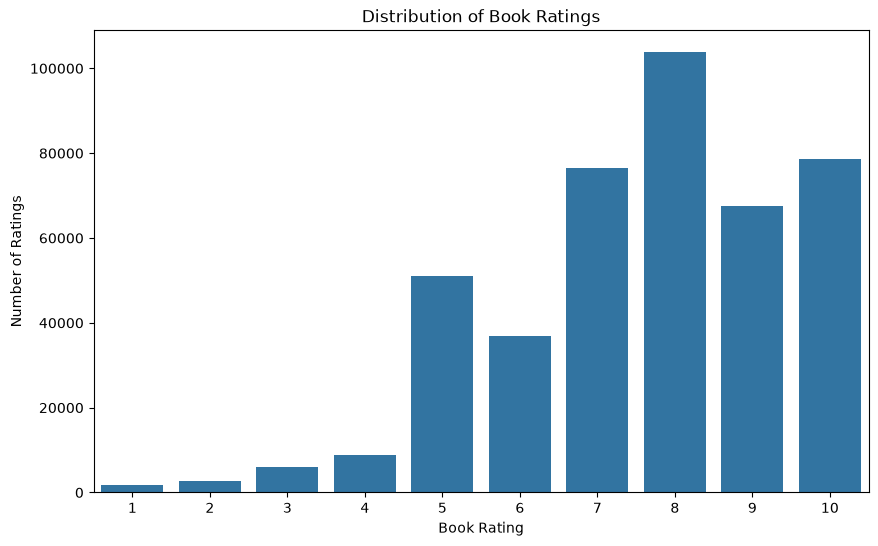

In [40]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x=ratings_explicit["Book-Rating"]
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [41]:
popular_books = book_rating_stats[
    ["Book-Title", "Book-Author", "Rating-Count", "Average-Rating"]
].copy()

popular_books.head()

,Book-Title,Book-Author,Rating-Count,Average-Rating
0,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,77,7.805195
1,The Boy Next Door,Meggin Cabot,53,8.132075
2,"Men Are from Mars, Women Are from Venus: A Pra...",John Gray,57,6.947368
3,Divine Secrets of the Ya-Ya Sisterhood : A Novel,Rebecca Wells,59,7.610169
4,The Poisonwood Bible,Barbara Kingsolver,78,8.384615


In [42]:
popular_books = popular_books.sort_values(
    by="Average-Rating",
    ascending=False
)

In [43]:
popular_books.head(10)

,Book-Title,Book-Author,Rating-Count,Average-Rating
114,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,77,9.402597
246,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,137,9.262774
249,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,53,9.207547
113,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,83,9.120482
245,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,133,9.082707
33,Charlotte's Web (Trophy Newbery),E. B. White,68,9.073529
244,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,141,9.035461
248,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,206,9.033981
412,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,119,8.983193
59,The Little Prince,Antoine de Saint-ExupÃÂ©ry,51,8.980392


In [44]:
C = book_rating_stats["Average-Rating"].mean()

print("Overall Average Rating:", C)

Overall Average Rating: 7.810282003554084


In [45]:
m = 50

In [46]:
m = 50

book_rating_stats["Weighted-Rating"] = (
    (book_rating_stats["Rating-Count"] /
     (book_rating_stats["Rating-Count"] + m))
    * book_rating_stats["Average-Rating"]
    +
    (m /
     (book_rating_stats["Rating-Count"] + m))
    * C
)

In [47]:
book_rating_stats.head()

,ISBN,Rating-Count,Average-Rating,Book-Title,Book-Author,Weighted-Rating
0,002542730X,77,7.805195,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,7.807198
1,0060096195,53,8.132075,The Boy Next Door,Meggin Cabot,7.975865
2,006016848X,57,6.947368,"Men Are from Mars, Women Are from Venus: A Pra...",John Gray,7.350599
3,0060173289,59,7.610169,Divine Secrets of the Ya-Ya Sisterhood : A Novel,Rebecca Wells,7.701964
4,0060175400,78,8.384615,The Poisonwood Bible,Barbara Kingsolver,8.160266


In [48]:
weighted_books = book_rating_stats.sort_values(
    by="Weighted-Rating",
    ascending=False
)

weighted_books.head(10)

,ISBN,Rating-Count,Average-Rating,Book-Title,Book-Author,Weighted-Rating
246,0439139597,137,9.262774,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,8.874407
248,043935806X,206,9.033981,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,8.794977
413,059035342X,313,8.939297,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,8.783785
114,0345339738,77,9.402597,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,8.775702
245,0439136369,133,9.082707,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,8.735050
289,0446310786,214,8.943925,To Kill a Mockingbird,Harper Lee,8.729220
244,0439136350,141,9.035461,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,8.714734
412,0590353403,119,8.983193,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,8.636178
113,0345339711,83,9.120482,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,8.627926
242,0439064864,126,8.920635,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,8.605194


## 6. User and Book Filtering

Filter users and books based on the
minimum number of ratings to improve
the reliability of recommendations.

In [49]:
user_rating_counts = ratings_explicit["User-ID"].value_counts()

user_rating_counts.head(10)

User-ID
11676     8524
98391     5802
153662    1969
189835    1906
23902     1395
76499     1036
171118    1035
235105    1023
16795      968
248718     948
Name: count, dtype: int64

In [50]:
user_rating_counts.describe()

count    77805.000000
mean         5.573819
std         44.001879
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       8524.000000
Name: count, dtype: float64

In [51]:
(user_rating_counts >= 5).sum()

np.int64(14220)

In [52]:
book_rating_counts = ratings_explicit["ISBN"].value_counts()

(book_rating_counts >= 5).sum()

np.int64(14535)

In [53]:
user_rating_counts = ratings_explicit["User-ID"].value_counts()

In [54]:
user_rating_counts.describe()

count    77805.000000
mean         5.573819
std         44.001879
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       8524.000000
Name: count, dtype: float64

In [55]:
(user_rating_counts >= 5).sum()

np.int64(14220)

In [56]:
book_rating_counts = ratings_explicit["ISBN"].value_counts()
(book_rating_counts >= 5).sum()

np.int64(14535)

In [57]:
print("Users with at least 10 ratings:",
      (user_rating_counts >= 10).sum())

Users with at least 10 ratings: 7334


In [58]:
print("Books with at least 10 ratings:",
      (book_rating_counts >= 10).sum())

Books with at least 10 ratings: 5645


In [59]:
print("Users with at least 20 ratings:",
      (user_rating_counts >= 20).sum())

Users with at least 20 ratings: 3704


In [60]:
print("Books with at least 20 ratings:",
      (book_rating_counts >= 20).sum())

Books with at least 20 ratings: 2179


In [61]:
active_users = user_rating_counts[
    user_rating_counts >= 10
].index

ratings_filtered = ratings_explicit[
    ratings_explicit["User-ID"].isin(active_users)
].copy()

print("Ratings after user filtering:", ratings_filtered.shape)

Ratings after user filtering: (295561, 3)


In [62]:
book_counts_filtered = ratings_filtered["ISBN"].value_counts()

popular_isbns = book_counts_filtered[
    book_counts_filtered >= 10
].index

ratings_filtered = ratings_filtered[
    ratings_filtered["ISBN"].isin(popular_isbns)
].copy()

print("Final ratings:", ratings_filtered.shape)
print("Users:", ratings_filtered["User-ID"].nunique())
print("Books:", ratings_filtered["ISBN"].nunique())

Final ratings: (74907, 3)
Users: 6570
Books: 3411


## 7. User-Book Matrix Creation

Create a user-book interaction matrix
where rows represent users and columns
represent books.

In [63]:
user_book_matrix = ratings_filtered.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

In [64]:
user_book_matrix = ratings_filtered.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

print("Matrix shape:", user_book_matrix.shape)
user_book_matrix.head()

Matrix shape: (6570, 3411)


ISBN,000649840X,0006514855,0007110928,0007154615,0020198906,0020199600,0020427859,0020442009,0020442203,0020442602,...,3551551685,3596259924,3746614007,8408043641,8432206407,8445071416,8472236552,8478886451,8495501090,8495501198
User-ID,,,,,,,,,,,,,,,,,,,,,
242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:
user_book_matrix = ratings_filtered.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

print("Matrix shape:", user_book_matrix.shape)

Matrix shape: (6570, 3411)


## 8. Cosine Similarity Calculation

Calculate cosine similarity between books
using user rating patterns to identify
similar books.

In [66]:
from sklearn.metrics.pairwise import cosine_similarity

In [67]:
book_matrix_filled = user_book_matrix.fillna(0)

In [68]:
book_similarity = cosine_similarity(book_matrix_filled.T)

print("Similarity matrix shape:", book_similarity.shape)

Similarity matrix shape: (3411, 3411)


In [69]:
book_info = books_clean[[
    "ISBN",
    "Book-Title",
    "Book-Author"
]].drop_duplicates("ISBN")

book_info.head()

,ISBN,Book-Title,Book-Author
0,0195153448,Classical Mythology,Mark P. O. Morford
1,0002005018,Clara Callan,Richard Bruce Wright
2,0060973129,Decision in Normandy,Carlo D'Este
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata
4,0393045218,The Mummies of Urumchi,E. J. W. Barber


In [70]:
isbn_to_title = dict(
    zip(book_info["ISBN"], book_info["Book-Title"])
)

title_to_isbn = dict(
    zip(book_info["Book-Title"], book_info["ISBN"])
)

## 9. Building the Recommendation Function

Develop a recommendation function that
accepts a book title and returns the
top similar books with their authors
and similarity scores.

In [71]:
def recommend_books(book_title, n=10):

    if book_title not in title_to_isbn:
        print("This book is not available in the filtered recommendation dataset.")
        return

    isbn = title_to_isbn[book_title]

    book_index = user_book_matrix.columns.get_loc(isbn)

    similarity_scores = book_similarity[book_index]

    similar_indices = similarity_scores.argsort()[::-1]

    recommendations = []
    seen_titles = set()

    for index in similar_indices:

        similar_isbn = user_book_matrix.columns[index]

        if similar_isbn == isbn:
            continue

        title = isbn_to_title.get(similar_isbn)

        if title and title not in seen_titles:

            author = book_info_filtered.loc[
                book_info_filtered["ISBN"] == similar_isbn,
                "Book-Author"
            ].iloc[0]

            score = similarity_scores[index]

            recommendations.append({
                "Book Title": title,
                "Author": author,
                "Similarity Score": round(score, 4)
            })

            seen_titles.add(title)

        if len(recommendations) == n:
            break

    return pd.DataFrame(recommendations)

In [72]:
books_clean["Book-Title"].head(20).tolist()

['Classical Mythology',
 'Clara Callan',
 'Decision in Normandy',
 'Flu: The Story of the Great Influenza Pandemic of 1918 and the Search for the Virus That Caused It',
 'The Mummies of Urumchi',
 "The Kitchen God's Wife",
 "What If?: The World's Foremost Military Historians Imagine What Might Have Been",
 'PLEADING GUILTY',
 'Under the Black Flag: The Romance and the Reality of Life Among the Pirates',
 "Where You'll Find Me: And Other Stories",
 'Nights Below Station Street',
 "Hitler's Secret Bankers: The Myth of Swiss Neutrality During the Holocaust",
 'The Middle Stories',
 'Jane Doe',
 "A Second Chicken Soup for the Woman's Soul (Chicken Soup for the Soul Series)",
 'The Witchfinder (Amos Walker Mystery Series)',
 'More Cunning Than Man: A Social History of Rats and Man',
 'Goodbye to the Buttermilk Sky',
 'The Testament',
 'Beloved (Plume Contemporary Fiction)']

In [73]:
# Get only the books that are present in our recommendation matrix
available_isbns = set(user_book_matrix.columns)

book_info_filtered = book_info[
    book_info["ISBN"].isin(available_isbns)
].copy()

print("Books available for recommendation:", len(book_info_filtered))

Books available for recommendation: 3331


In [74]:
title_to_isbn = dict(
    zip(
        book_info_filtered["Book-Title"],
        book_info_filtered["ISBN"]
    )
)

isbn_to_title = dict(
    zip(
        book_info_filtered["ISBN"],
        book_info_filtered["Book-Title"]
    )
)

In [75]:
book_info_filtered[["ISBN", "Book-Title", "Book-Author"]].head(20)

,ISBN,Book-Title,Book-Author
5,0399135782,The Kitchen God's Wife,Amy Tan
18,0440234743,The Testament,John Grisham
19,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
20,0609804618,Our Dumb Century: The Onion Presents 100 Years...,The Onion
26,0971880107,Wild Animus,Rich Shapero
27,0345402871,Airframe,Michael Crichton
28,0345417623,Timeline,MICHAEL CRICHTON
37,0446310786,To Kill a Mockingbird,Harper Lee
38,0449005615,Seabiscuit: An American Legend,LAURA HILLENBRAND
45,0671888587,I'll Be Seeing You,Mary Higgins Clark


In [76]:
recommend_books("The Kitchen God's Wife",10)

,Book Title,Author,Similarity Score
0,The Joy Luck Club,Amy Tan,0.1999
1,The Adventures of Tom Sawyer (Adventures of To...,MARK TWAIN,0.1768
2,The Hundred Secret Senses,Amy Tan,0.1640
3,The Bonesetter's Daughter,Amy Tan,0.1593
4,The Cider House Rules,John Irving,0.1529
5,Talk Before Sleep: A Novel,Elizabeth Berg,0.1301
6,The Firm,John Grisham,0.1273
7,One Hundred Years of Solitude,Gabriel Garcia Marquez,0.1235
8,The Awakening,Kate Chopin,0.1190
9,The Inn at Lake Devine,Elinor Lipman,0.1182


In [77]:
similarity_values = book_similarity[np.triu_indices_from(book_similarity, k=1)]

print("Mean Similarity:", similarity_values.mean())
print("Maximum Similarity:", similarity_values.max())
print("Minimum Similarity:", similarity_values.min())

Mean Similarity: 0.016611723806290685
Maximum Similarity: 0.8863793390845569
Minimum Similarity: 0.0


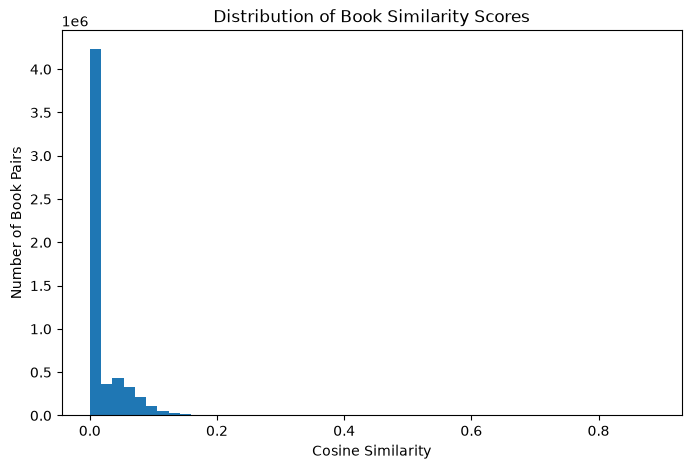

In [78]:
plt.figure(figsize=(8, 5))

plt.hist(similarity_values, bins=50)

plt.title("Distribution of Book Similarity Scores")
plt.xlabel("Cosine Similarity")
plt.ylabel("Number of Book Pairs")

plt.show()

In [79]:

def recommend_books(book_title, n=10):

    # Step 1: Find the selected book
    book_data = book_info_filtered[
        book_info_filtered["Book-Title"].str.lower() == book_title.lower()
    ]

    if book_data.empty:
        print("Book not found in the dataset.")
        return

    # Step 2: Find ISBNs available in the recommendation matrix
    available_isbns = set(user_book_matrix.columns.astype(str))

    matching_isbns = [
        str(isbn) for isbn in book_data["ISBN"]
        if str(isbn) in available_isbns
    ]

    if not matching_isbns:
        print("Book is not available in the recommendation matrix.")
        return

    isbn = matching_isbns[0]

    # Step 3: Get the position of the selected book
    book_index = user_book_matrix.columns.astype(str).get_loc(isbn)

    # Step 4: Get similarity scores
    similarity_scores = book_similarity[book_index]

    # Step 5: Sort books by similarity score
    similar_indices = similarity_scores.argsort()[::-1]

    recommendations = []

    # Step 6: Generate top recommendations
    for index in similar_indices:

        if index == book_index:
            continue

        similar_isbn = str(user_book_matrix.columns[index])

        similar_book = book_info_filtered[
            book_info_filtered["ISBN"].astype(str) == similar_isbn
        ]

        if not similar_book.empty:

            recommendations.append({
                "Book Title": similar_book.iloc[0]["Book-Title"],
                "Author": similar_book.iloc[0]["Book-Author"],
                "Similarity Score": round(float(similarity_scores[index]), 4)
            })

        if len(recommendations) == n:
            break

    return pd.DataFrame(recommendations)


In [80]:
recommend_books("The Joy Luck Club", 10)

,Book Title,Author,Similarity Score
0,The Hundred Secret Senses,Amy Tan,0.2084
1,The Kitchen God's Wife,Amy Tan,0.1999
2,The Sparrow,MARY DORIA RUSSELL,0.1071
3,"All the Pretty Horses (The Border Trilogy, Vol 1)",CORMAC MCCARTHY,0.1049
4,H Is for Homicide (Kinsey Millhone Mysteries (...,Sue Grafton,0.1048
5,The Great Gatsby,F. Scott Fitzgerald,0.1029
6,The Book of Three (Chronicles of Prydain (Pape...,LLOYD ALEXANDER,0.1024
7,The Bonesetter's Daughter,Amy Tan,0.1001
8,Fox in Socks (I Can Read It All by Myself Begi...,Dr. Seuss,0.0998
9,The Chosen,Chaim Potok,0.0983


In [81]:
recommend_books("The Firm", 10)

,Book Title,Author,Similarity Score
0,The Client,John Grisham,0.3856
1,Mixed Blessings,DANIELLE STEEL,0.2842
2,Enchanted: The Donovan Legacy (Intimate Moment...,Nora Roberts,0.2451
3,Remembrance,Danielle Steel,0.2447
4,The Partner,John Grisham,0.2383
5,Dangerous,Nora Roberts,0.2375
6,The Macgregors: Serena - Caine (The Macgregors),Nora Roberts,0.2314
7,Thurston House,Danielle Steel,0.2308
8,Envy,Sandra Brown,0.2302
9,The Macgregors: Alan - Grant (The Macgregors),Nora Roberts,0.2275


In [82]:
recommend_books("The Cider House Rules", 10)

,Book Title,Author,Similarity Score
0,Le Divorce (William Abrahams Book),Diane Johnson,0.2160
1,Star,Danielle Steel,0.1738
2,All Quiet on the Western Front,Erich Maria Remarque,0.1671
3,Heartbeat,Danielle Steel,0.1569
4,Sophie's Choice,William Styron,0.1539
5,The Kitchen God's Wife,Amy Tan,0.1529
6,Colony,Anne Rivers Siddons,0.1490
7,Krakatoa : The Day the World Exploded: August ...,Simon Winchester,0.1466
8,Out to Canaan (The Mitford Years),Jan Karon,0.1424
9,The Music of the Spheres,Elizabeth Redfern,0.1420


In [83]:
recommend_books("Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))", 10)

,Book Title,Author,Similarity Score
0,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.3666
1,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.3165
2,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.2334
3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.2238
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.2181
5,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.1809
6,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.1755
7,Fried Green Tomatoes at the Whistle Stop Cafe,Fannie Flagg,0.1351
8,Love Story,Erich Segal,0.1338
9,Anne of Ingleside (Anne of Green Gables Novels...,L.M. MONTGOMERY,0.1167


In [84]:
recommend_books("Python Programming XYZ", 10)

Book not found in the dataset.


## 10. Model Evaluation

Split the ratings dataset into training
and testing sets and evaluate the
recommendation system using Precision@10
and Recall@10.

In [85]:

from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    ratings_filtered,
    test_size=0.2,
    random_state=42
)

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)


Training data: (59925, 3)
Testing data: (14982, 3)


In [86]:

# Create User-Book Matrix using training data

train_user_book_matrix = train_data.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
).fillna(0)

print("Training Matrix Shape:", train_user_book_matrix.shape)


Training Matrix Shape: (6436, 3411)


In [87]:

from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between books
train_book_similarity = cosine_similarity(
    train_user_book_matrix.T
)

print("Training Similarity Matrix Shape:",
      train_book_similarity.shape)


Training Similarity Matrix Shape: (3411, 3411)


In [88]:
# Select relevant books from test data
relevant_test_data = test_data[test_data["Book-Rating"] >= 7]

# Keep only books available in the training matrix
relevant_test_data = relevant_test_data[
    relevant_test_data["ISBN"].astype(str).isin(
        train_user_book_matrix.columns.astype(str)
    )
]

print("Relevant Test Ratings:", len(relevant_test_data))
print("Users with Relevant Test Ratings:",
      relevant_test_data["User-ID"].nunique())
print("Relevant Books:", relevant_test_data["ISBN"].nunique())

Relevant Test Ratings: 12039
Users with Relevant Test Ratings: 4117
Relevant Books: 3132


In [89]:
# Create a dictionary of relevant books for each user
actual_books = (
    relevant_test_data
    .groupby("User-ID")["ISBN"]
    .apply(lambda x: set(x.astype(str)))
    .to_dict()
)

# Create a lookup for training users
train_user_ids = set(train_user_book_matrix.index)

# Count users available for evaluation
evaluation_users = [
    user_id for user_id in actual_books
    if user_id in train_user_ids
]

print("Users available for evaluation:", len(evaluation_users))

Users available for evaluation: 3998


In [90]:
import numpy as np

precision_scores = []
recall_scores = []

# Convert ISBN columns to strings for matching
train_isbns = train_user_book_matrix.columns.astype(str)

for user_id in evaluation_users:

    # Get the user's training ratings
    user_ratings = train_user_book_matrix.loc[user_id].values

    # Calculate recommendation scores
    scores = user_ratings @ train_book_similarity

    # Exclude books already rated by the user
    rated_indices = np.where(user_ratings > 0)[0]
    scores[rated_indices] = -np.inf

    # Get top 10 recommended books
    top_indices = np.argsort(scores)[::-1][:10]
    recommended_books = set(train_isbns[top_indices])

    # Get books actually liked by the user
    actual = actual_books[user_id]

    # Calculate common books
    hits = len(recommended_books.intersection(actual))

    precision_scores.append(hits / 10)
    recall_scores.append(hits / len(actual))

# Calculate average evaluation scores
precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)

print("Precision@10:", round(precision_at_10, 4))
print("Recall@10:", round(recall_at_10, 4))

Precision@10: 0.0257
Recall@10: 0.0915


In [91]:
print("Total users evaluated:", len(evaluation_users))

print("Average relevant books per user:",
      round(np.mean([
          len(actual_books[user_id])
          for user_id in evaluation_users
      ]), 2))

print("Average Precision@10:",
      round(precision_at_10, 4))

print("Average Recall@10:",
      round(recall_at_10, 4))

Total users evaluated: 3998
Average relevant books per user: 2.98
Average Precision@10: 0.0257
Average Recall@10: 0.0915


In [92]:
weighted_precision = []
weighted_recall = []

for user_id in evaluation_users:

    # Get the user's training ratings
    user_ratings = train_user_book_matrix.loc[user_id].values

    # Identify books already rated
    rated_mask = (user_ratings > 0)

    # Calculate weighted recommendation scores
    numerator = user_ratings @ train_book_similarity
    denominator = rated_mask.astype(float) @ train_book_similarity

    # Calculate weighted average scores
    scores = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=float),
        where=denominator > 0
    )

    # Exclude previously rated books and unsupported candidates
    scores[(rated_mask) | (denominator <= 0)] = -np.inf

    # Select top 10 books
    top_indices = np.argsort(scores)[::-1][:10]
    recommended_books = set(train_isbns[top_indices])

    # Compare with relevant test books
    actual = actual_books[user_id]
    hits = len(recommended_books.intersection(actual))

    weighted_precision.append(hits / 10)
    weighted_recall.append(hits / len(actual))

# Calculate final metrics
new_precision = np.mean(weighted_precision)
new_recall = np.mean(weighted_recall)

print("Improved Precision@10:", round(new_precision, 4))
print("Improved Recall@10:", round(new_recall, 4))

Improved Precision@10: 0.0006
Improved Recall@10: 0.0025


In [93]:
# Select one evaluation user
sample_user = evaluation_users[0]

# Get user's training ratings
user_ratings = train_user_book_matrix.loc[sample_user].values

# Calculate original scores
original_scores = user_ratings @ train_book_similarity

# Calculate weighted scores
numerator = user_ratings @ train_book_similarity
denominator = (
    (user_ratings > 0).astype(float) @ train_book_similarity
)

weighted_scores = np.divide(
    numerator,
    denominator,
    out=np.zeros_like(numerator, dtype=float),
    where=denominator > 0
)

# Exclude already-rated books
rated_mask = user_ratings > 0
original_scores[rated_mask] = -np.inf
weighted_scores[rated_mask] = -np.inf

print("Sample User:", sample_user)
print("Original Top Score:", np.max(original_scores))
print("Weighted Top Score:", np.max(weighted_scores))
print("Original Mean Score:", np.mean(original_scores[np.isfinite(original_scores)]))
print("Weighted Mean Score:", np.mean(weighted_scores[np.isfinite(weighted_scores)]))

Sample User: 243
Original Top Score: 5.039957044329656
Weighted Top Score: 10.0
Original Mean Score: 1.1666246232304158
Weighted Mean Score: 6.438188428192202


In [94]:
# Get ISBNs for top 10 recommendations
original_top10 = np.argsort(original_scores)[::-1][:10]
weighted_top10 = np.argsort(weighted_scores)[::-1][:10]

# Convert ISBNs into readable book titles
def get_book_titles(indices):
    titles = []

    for index in indices:
        isbn = str(train_isbns[index])

        book = book_info_filtered[
            book_info_filtered["ISBN"].astype(str) == isbn
        ]

        if not book.empty:
            titles.append(book.iloc[0]["Book-Title"])

    return titles


print("Original Recommendations:")
for title in get_book_titles(original_top10):
    print("-", title)

print("\nWeighted Recommendations:")
for title in get_book_titles(weighted_top10):
    print("-", title)

Original Recommendations:
- We Were the Mulvaneys
- Enduring Love
- The Rapture of Canaan
- From Potter's Field
- Esperanza Rising
- The Sexual Life of Catherine M.
- Point of Origin
- The Shell Seekers (Shell Seekers)
- The Loop: A Novel
- The Fulfillment

Weighted Recommendations:
- The Robber Bride
- Letters from the Earth
- Breakfast of Champions
- The Giver (Readers Circle)
- The Claiming of Sleeping Beauty (Sleeping Beauty)
- Cat's Cradle
- Guilty Pleasures (Anita Blake Vampire Hunter (Paperback))
- Fatherland
- With a Tangled Skein (Incarnations of Immortality (Paperback))
- Wielding a Red Sword (Incarnations of Immortality (Paperback))


In [95]:
sample_actual_books = relevant_test_data[
    relevant_test_data["User-ID"] == sample_user
]

sample_actual_books = sample_actual_books.merge(
    books_clean[["ISBN", "Book-Title"]],
    on="ISBN",
    how="left"
)

print("Books actually liked by User:", sample_user)

display(
    sample_actual_books[
        ["Book-Title", "Book-Rating"]
    ].drop_duplicates()
)

Books actually liked by User: 243


,Book-Title,Book-Rating
0,The Pilot's Wife : A Novel,9
1,The Bean Trees,10


In [96]:
actual_sample = set(
    sample_actual_books["ISBN"].astype(str)
)

original_recommended = set(
    train_isbns[original_top10]
)

weighted_recommended = set(
    train_isbns[weighted_top10]
)

print("Original Model Hits:",
      len(actual_sample.intersection(original_recommended)))

print("Weighted Model Hits:",
      len(actual_sample.intersection(weighted_recommended)))

print("Relevant Books:", len(actual_sample))

Original Model Hits: 0
Weighted Model Hits: 0
Relevant Books: 2


In [97]:
# Check whether User 243's relevant books exist in training data

for isbn in actual_sample:
    if isbn in train_isbns:
        print(isbn, "- Available in training matrix")
    else:
        print(isbn, "- Not available in training matrix")

0060915544 - Available in training matrix
0316601950 - Available in training matrix


In [98]:
# Get relevant book indices
for isbn in actual_sample:

    book_index = train_isbns.get_loc(isbn)

    # Similarity of this book with all other books
    similarities = train_book_similarity[book_index]

    # Get books rated by User 243
    rated_indices = np.where(user_ratings > 0)[0]

    # Sort by similarity
    top_similar = rated_indices[
        np.argsort(similarities[rated_indices])[::-1][:5]
    ]

    print("\nRelevant ISBN:", isbn)

    for index in top_similar:
        print(
            train_isbns[index],
            "Similarity:",
            round(similarities[index], 4)
        )


Relevant ISBN: 0060915544
0385720106 Similarity: 0.0705
0425163407 Similarity: 0.0589
0060977493 Similarity: 0.0444
0316899984 Similarity: 0.0421
155874262X Similarity: 0.0305

Relevant ISBN: 0316601950
0316899984 Similarity: 0.0866
0385720106 Similarity: 0.0614
044023722X Similarity: 0.0543
0316776963 Similarity: 0.0465
0446364800 Similarity: 0.046


In [99]:
# Check training ratings for the two relevant books

for isbn in actual_sample:

    rating_count = (
        train_data["ISBN"].astype(str) == isbn
    ).sum()

    print("ISBN:", isbn)
    print("Training ratings:", rating_count)
    print("-------------------------")

ISBN: 0060915544
Training ratings: 50
-------------------------
ISBN: 0316601950
Training ratings: 105
-------------------------


## 11. Model Comparison

Compare the original and weighted
Item-Based Collaborative Filtering
approaches using evaluation metrics.

In [100]:
model_comparison = pd.DataFrame({
    "Model": [
        "Original Item-Based Collaborative Filtering",
        "Weighted Item-Based Collaborative Filtering"
    ],
    "Precision@10": [
        precision_at_10,
        new_precision
    ],
    "Recall@10": [
        recall_at_10,
        new_recall
    ]
})

display(model_comparison)

,Model,Precision@10,Recall@10
0,Original Item-Based Collaborative Filtering,0.025688,0.091526
1,Weighted Item-Based Collaborative Filtering,0.000575,0.002463


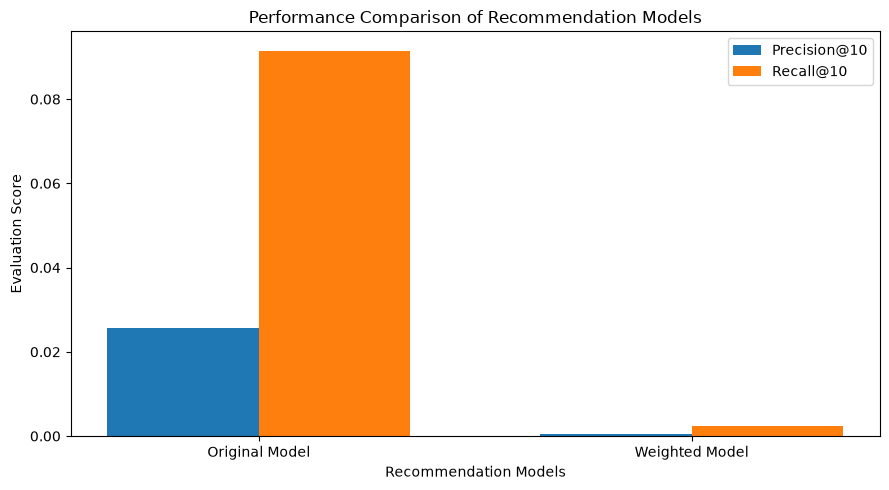

In [101]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Original Model",
    "Weighted Model"
]

precision = [
    precision_at_10,
    new_precision
]

recall = [
    recall_at_10,
    new_recall
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, precision, width, label="Precision@10")
plt.bar(x + width/2, recall, width, label="Recall@10")

plt.xlabel("Recommendation Models")
plt.ylabel("Evaluation Score")
plt.title("Performance Comparison of Recommendation Models")
plt.xticks(x, models)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Sample Book Recommendations

Test the recommendation system using
different book titles and display
the top recommended books.

In [102]:
test_books = [
    "The Joy Luck Club",
    "The Kitchen God's Wife",
    "The Firm"
]

for book in test_books:
    print("\nRecommendations for:", book)

    result = recommend_books(book, 5)

    if result is not None:
        display(result)


Recommendations for: The Joy Luck Club


,Book Title,Author,Similarity Score
0,The Hundred Secret Senses,Amy Tan,0.2084
1,The Kitchen God's Wife,Amy Tan,0.1999
2,The Sparrow,MARY DORIA RUSSELL,0.1071
3,"All the Pretty Horses (The Border Trilogy, Vol 1)",CORMAC MCCARTHY,0.1049
4,H Is for Homicide (Kinsey Millhone Mysteries (...,Sue Grafton,0.1048



Recommendations for: The Kitchen God's Wife


,Book Title,Author,Similarity Score
0,Memoirs of a Geisha,Arthur Golden,0.2422
1,The Hundred Secret Senses,Amy Tan,0.2378
2,Galileo's Daughter: A Historical Memoir of Sci...,Dava Sobel,0.2373
3,Joy Luck Club,Amy Tan,0.2269
4,The Witch of Blackbird Pond (Laurel Leaf Books),ELIZABETH GEORGE SPEARE,0.2135



Recommendations for: The Firm


,Book Title,Author,Similarity Score
0,The Client,John Grisham,0.3856
1,Mixed Blessings,DANIELLE STEEL,0.2842
2,Enchanted: The Donovan Legacy (Intimate Moment...,Nora Roberts,0.2451
3,Remembrance,Danielle Steel,0.2447
4,The Partner,John Grisham,0.2383


In [103]:
sample_recommendations = []

for book in test_books:
    recommendations = recommend_books(book, 5)

    if recommendations is not None:
        recommendations = recommendations.copy()
        recommendations.insert(0, "Input Book", book)
        sample_recommendations.append(recommendations)

final_recommendation_table = pd.concat(
    sample_recommendations,
    ignore_index=True
)

display(final_recommendation_table)

,Input Book,Book Title,Author,Similarity Score
0,The Joy Luck Club,The Hundred Secret Senses,Amy Tan,0.2084
1,The Joy Luck Club,The Kitchen God's Wife,Amy Tan,0.1999
2,The Joy Luck Club,The Sparrow,MARY DORIA RUSSELL,0.1071
3,The Joy Luck Club,"All the Pretty Horses (The Border Trilogy, Vol 1)",CORMAC MCCARTHY,0.1049
4,The Joy Luck Club,H Is for Homicide (Kinsey Millhone Mysteries (...,Sue Grafton,0.1048
5,The Kitchen God's Wife,Memoirs of a Geisha,Arthur Golden,0.2422
6,The Kitchen God's Wife,The Hundred Secret Senses,Amy Tan,0.2378
7,The Kitchen God's Wife,Galileo's Daughter: A Historical Memoir of Sci...,Dava Sobel,0.2373
8,The Kitchen God's Wife,Joy Luck Club,Amy Tan,0.2269
9,The Kitchen God's Wife,The Witch of Blackbird Pond (Laurel Leaf Books),ELIZABETH GEORGE SPEARE,0.2135


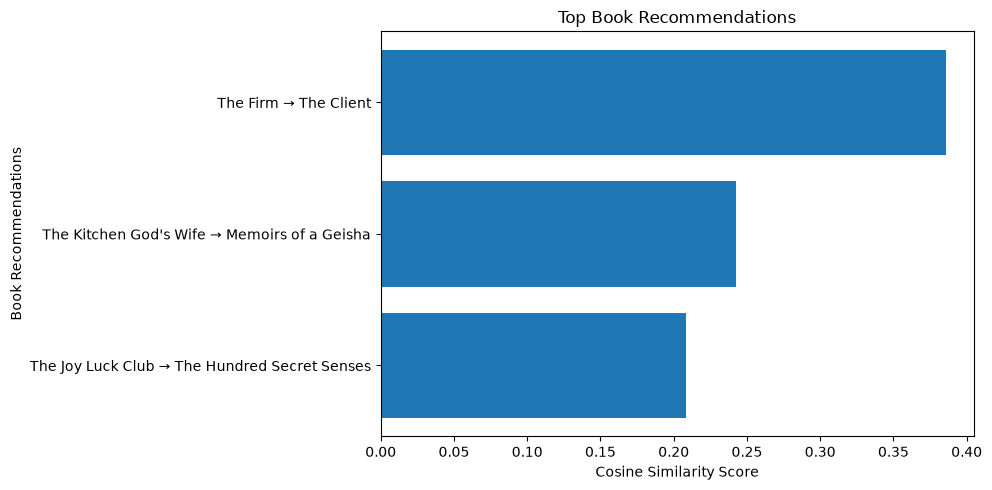

In [104]:
import matplotlib.pyplot as plt

# Get the highest-scoring recommendation for each input book
top_recommendations = (
    final_recommendation_table
    .sort_values("Similarity Score", ascending=False)
    .groupby("Input Book")
    .head(1)
)

plt.figure(figsize=(10, 5))

labels = (
    top_recommendations["Input Book"]
    + " → "
    + top_recommendations["Book Title"]
)

plt.barh(
    labels,
    top_recommendations["Similarity Score"]
)

plt.xlabel("Cosine Similarity Score")
plt.ylabel("Book Recommendations")
plt.title("Top Book Recommendations")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 13. Conclusion

The project successfully demonstrates
an Item-Based Collaborative Filtering
recommendation system using cosine
similarity.

## 14. Limitations

Discuss cold start problems, data sparsity,
popularity bias and recommendation quality.

## 15. Future Scope

Explore hybrid recommendation systems,
advanced algorithms and web application
development for future improvements.